In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import pyarrow

In [2]:
raw_data = pd.read_csv('./data/all_v2.csv')
raw_data.head()


,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
0,6050000,2018-02-19,20:00:21,59.805808,30.376141,2661,1,8,10,3,82.6,10.8,1
1,8650000,2018-02-27,12:04:54,55.683807,37.297405,81,3,5,24,2,69.1,12.0,1
2,4000000,2018-02-28,15:44:00,56.295250,44.061637,2871,1,5,9,3,66.0,10.0,1
3,1850000,2018-03-01,11:24:52,44.996132,39.074783,2843,4,12,16,2,38.0,5.0,11
4,5450000,2018-03-01,17:42:43,55.918767,37.984642,81,3,13,14,2,60.0,10.0,1


In [3]:
data = raw_data[raw_data['region'] == 3].copy()
data.info()

<class 'pandas.DataFrame'>
Index: 439511 entries, 6 to 5477005
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   price          439511 non-null  int64  
 1   date           439511 non-null  str    
 2   time           439511 non-null  str    
 3   geo_lat        439511 non-null  float64
 4   geo_lon        439511 non-null  float64
 5   region         439511 non-null  int64  
 6   building_type  439511 non-null  int64  
 7   level          439511 non-null  int64  
 8   levels         439511 non-null  int64  
 9   rooms          439511 non-null  int64  
 10  area           439511 non-null  float64
 11  kitchen_area   439511 non-null  float64
 12  object_type    439511 non-null  int64  
dtypes: float64(4), int64(7), str(2)
memory usage: 54.6 MB


In [4]:
data.duplicated().sum()

np.int64(430)

In [5]:
data = data.drop_duplicates()

In [6]:
FLAT_KEY = ["geo_lat", "geo_lon", "level", "levels", "rooms",
            "area", "kitchen_area", "building_type"]



In [7]:
data["dt"] = pd.to_datetime(data["date"] + " " + data["time"])
is_new = data["object_type"] == 11
data = data.sort_values("dt")

secondary = data[~is_new].drop_duplicates(subset=FLAT_KEY, keep="last")
new = data[is_new].drop_duplicates(subset=FLAT_KEY + ["price"], keep="last")

data = pd.concat([secondary, new])

data.describe()

C:\Temp\ipykernel_21852\3543490394.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  secondary = data[~is_new].drop_duplicates(subset=FLAT_KEY, keep="last")
C:\Temp\ipykernel_21852\3543490394.py:6: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  new = data[is_new].drop_duplicates(subset=FLAT_KEY + ["price"], keep="last")


,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,dt
count,3.931990e+05,393199.000000,393199.000000,393199.0,393199.000000,393199.000000,393199.000000,393199.000000,393199.000000,393199.000000,393199.000000,393199
mean,1.312533e+07,55.720822,37.576376,3.0,1.847266,8.686309,16.503753,1.861004,58.640476,12.262204,5.501639,2020-01-03 13:19:10.648180
min,-2.089967e+09,55.179939,36.836900,3.0,0.000000,1.000000,1.000000,-2.000000,1.400000,0.100000,1.000000,2018-03-04 12:35:25
25%,7.000000e+06,55.640461,37.478144,3.0,1.000000,4.000000,10.000000,1.000000,39.000000,8.000000,1.000000,2019-04-10 11:19:38
50%,9.400000e+06,55.725486,37.574046,3.0,2.000000,7.000000,16.000000,2.000000,53.400000,10.700000,1.000000,2019-12-19 09:15:07
75%,1.350000e+07,55.803803,37.681038,3.0,2.000000,12.000000,22.000000,3.000000,70.000000,15.700000,11.000000,2020-09-29 15:03:39.500000
max,1.096745e+09,56.655467,38.059246,3.0,5.000000,39.000000,39.000000,10.000000,5200.000000,1200.000000,11.000000,2021-05-01 20:14:15
std,1.916336e+07,0.108026,0.145758,0.0,0.785480,6.470679,7.576671,1.108445,36.303771,6.661693,4.975108,NaN


In [8]:
price_02_percentile = data['price'].quantile(0.002)
price_999_percentile = data['price'].quantile(0.999)
price_02_percentile, price_999_percentile


(np.float64(1100000.0), np.float64(233458755.20000246))

In [9]:
data = data[(data['price'] >= price_02_percentile) & (data['price'] <= price_999_percentile)]
data.describe()

,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,dt
count,3.920490e+05,392049.000000,392049.000000,392049.0,392049.000000,392049.000000,392049.000000,392049.000000,392049.000000,392049.000000,392049.000000,392049
mean,1.280119e+07,55.720775,37.576336,3.0,1.846320,8.694987,16.522970,1.858513,58.366812,12.244312,5.511911,2020-01-03 09:05:00.052840
min,1.100000e+06,55.179939,36.836900,3.0,0.000000,1.000000,1.000000,-2.000000,1.400000,0.100000,1.000000,2018-03-04 12:35:25
25%,7.000000e+06,55.640274,37.478124,3.0,1.000000,4.000000,10.000000,1.000000,39.000000,8.000000,1.000000,2019-04-09 20:31:36
50%,9.400000e+06,55.725464,37.573914,3.0,2.000000,7.000000,16.000000,2.000000,53.400000,10.700000,1.000000,2019-12-18 18:05:08
75%,1.350000e+07,55.803803,37.681106,3.0,2.000000,12.000000,22.000000,3.000000,70.000000,15.700000,11.000000,2020-09-29 14:40:25
max,2.333805e+08,56.655467,38.059246,3.0,5.000000,39.000000,39.000000,10.000000,4701.000000,150.000000,11.000000,2021-05-01 20:14:15
std,1.399767e+07,0.108082,0.145812,0.0,0.784751,6.473052,7.571787,1.104112,33.109089,6.330081,4.976126,NaN


In [10]:
data = data[data['rooms'] != -2]
data.describe()

,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,dt
count,3.919960e+05,391996.000000,391996.000000,391996.0,391996.000000,391996.000000,391996.000000,391996.000000,391996.000000,391996.000000,391996.000000,391996
mean,1.279316e+07,55.720771,37.576334,3.0,1.846231,8.695357,16.523972,1.859034,58.345945,12.243093,5.512444,2020-01-03 09:10:36.654662
min,1.100000e+06,55.179939,36.836900,3.0,0.000000,1.000000,1.000000,-1.000000,1.400000,0.100000,1.000000,2018-03-04 12:35:25
25%,7.000000e+06,55.640256,37.478124,3.0,1.000000,4.000000,10.000000,1.000000,39.000000,8.000000,1.000000,2019-04-09 19:22:24.250000
50%,9.400000e+06,55.725459,37.573904,3.0,2.000000,7.000000,16.000000,2.000000,53.400000,10.700000,1.000000,2019-12-18 18:34:13.500000
75%,1.350000e+07,55.803803,37.681144,3.0,2.000000,12.000000,22.000000,3.000000,70.000000,15.700000,11.000000,2020-09-29 14:40:29.750000
max,2.333805e+08,56.655467,38.059246,3.0,5.000000,39.000000,39.000000,10.000000,4701.000000,150.000000,11.000000,2021-05-01 20:14:15
std,1.396466e+07,0.108085,0.145818,0.0,0.784716,6.473144,7.571505,1.103275,32.983706,6.327140,4.976178,NaN


In [11]:
area_01_percentile = data['area'].quantile(0.001)
area_999_percentile = data['area'].quantile(0.999)

area_01_percentile, area_999_percentile

(np.float64(10.0), np.float64(313.0))

In [12]:
data = data[(data['area'] >= area_01_percentile) & (data['area'] <= area_999_percentile)]
data.describe()

,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,dt
count,3.913700e+05,391370.000000,391370.000000,391370.0,391370.000000,391370.000000,391370.000000,391370.000000,391370.000000,391370.000000,391370.000000,391370
mean,1.271103e+07,55.720749,37.576344,3.0,1.846059,8.695919,16.529783,1.856468,57.952415,12.227256,5.518154,2020-01-03 10:37:36.026785
min,1.100000e+06,55.179939,36.836900,3.0,0.000000,1.000000,1.000000,-1.000000,10.000000,0.100000,1.000000,2018-03-04 12:35:25
25%,7.000000e+06,55.640050,37.478124,3.0,1.000000,4.000000,10.000000,1.000000,39.000000,8.000000,1.000000,2019-04-09 16:34:35
50%,9.400000e+06,55.725422,37.573895,3.0,2.000000,7.000000,16.000000,2.000000,53.400000,10.700000,1.000000,2019-12-19 09:01:51
75%,1.350000e+07,55.803803,37.681359,3.0,2.000000,12.000000,22.000000,3.000000,70.000000,15.700000,11.000000,2020-09-29 16:04:41.250000
max,2.333805e+08,56.655467,38.059246,3.0,5.000000,39.000000,39.000000,9.000000,313.000000,124.000000,11.000000,2021-05-01 20:14:15
std,1.351423e+07,0.108100,0.145825,0.0,0.784499,6.472041,7.570096,1.098481,27.909318,6.243648,4.976735,NaN


In [13]:
(data['area'] < data['kitchen_area']).sum()

np.int64(20)

In [14]:
data = data[(data['area'] >= data['kitchen_area'])]
data.describe()

,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,dt
count,3.913500e+05,391350.000000,391350.000000,391350.0,391350.000000,391350.000000,391350.000000,391350.000000,391350.000000,391350.000000,391350.000000,391350
mean,1.271124e+07,55.720747,37.576340,3.0,1.846036,8.696078,16.530009,1.856476,57.952960,12.223573,5.518334,2020-01-03 10:43:28.665532
min,1.100000e+06,55.179939,36.836900,3.0,0.000000,1.000000,1.000000,-1.000000,10.000000,0.100000,1.000000,2018-03-04 12:35:25
25%,7.000000e+06,55.640050,37.478124,3.0,1.000000,4.000000,10.000000,1.000000,39.000000,8.000000,1.000000,2019-04-09 16:28:23.500000
50%,9.400000e+06,55.725422,37.573893,3.0,2.000000,7.000000,16.000000,2.000000,53.400000,10.700000,1.000000,2019-12-19 09:01:51
75%,1.350000e+07,55.803803,37.681347,3.0,2.000000,12.000000,22.000000,3.000000,70.000000,15.700000,11.000000,2020-09-29 16:07:51.250000
max,2.333805e+08,56.655467,38.059246,3.0,5.000000,39.000000,39.000000,9.000000,313.000000,103.130000,11.000000,2021-05-01 20:14:15
std,1.351451e+07,0.108100,0.145826,0.0,0.784472,6.472104,7.570126,1.098489,27.909728,6.220237,4.976752,NaN


In [15]:
per_point = data.groupby(["geo_lat", "geo_lon"]).size()
per_point.describe()
per_point.sort_values(ascending=False).head(20)   

geo_lat    geo_lon  
55.753960  37.620393    7660
55.754047  37.620405    4278
55.595142  37.448802    2714
55.570493  37.475423    2603
55.622106  37.427767    2446
55.562325  37.469841    2401
55.886918  37.534136    2322
55.625471  37.342814    2218
55.551660  37.540227    2030
55.541206  37.486610    1856
55.595242  37.448806    1832
55.668214  37.739177    1541
55.619589  37.417212    1430
55.881585  37.683930    1427
55.850284  37.685181    1372
55.696295  37.469712    1228
55.702798  37.872946    1187
55.602374  37.728472    1185
55.853728  37.620905    1161
55.662168  37.426220    1159
dtype: int64

In [16]:
bad_points = per_point.sort_values(ascending=False).index[[0, 1, 3]]  # позиции нужных строк в топе
idx = pd.MultiIndex.from_frame(data[["geo_lat", "geo_lon"]])
data = data[~idx.isin(bad_points)]


In [17]:
data.describe()

,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,dt
count,3.768090e+05,376809.000000,376809.000000,376809.0,376809.000000,376809.000000,376809.000000,376809.000000,376809.000000,376809.000000,376809.000000,376809
mean,1.267194e+07,55.720731,37.575642,3.0,1.842700,8.693972,16.488653,1.860497,57.921037,12.153368,5.377151,2019-12-29 11:02:51.979241
min,1.100000e+06,55.179939,36.836900,3.0,0.000000,1.000000,1.000000,-1.000000,10.000000,0.100000,1.000000,2018-03-04 12:35:25
25%,7.034940e+06,55.638567,37.476970,3.0,1.000000,4.000000,10.000000,1.000000,39.000000,8.000000,1.000000,2019-04-04 13:42:00
50%,9.400000e+06,55.722482,37.568713,3.0,2.000000,7.000000,16.000000,2.000000,53.300000,10.600000,1.000000,2019-12-07 10:42:45
75%,1.350000e+07,55.805338,37.683930,3.0,2.000000,12.000000,22.000000,3.000000,70.000000,15.400000,11.000000,2020-09-24 20:00:13
max,2.333805e+08,56.655467,38.059246,3.0,5.000000,39.000000,39.000000,9.000000,313.000000,103.130000,11.000000,2021-05-01 20:14:15
std,1.337130e+07,0.109296,0.148167,0.0,0.793825,6.483314,7.579515,1.096875,27.913190,6.177898,4.961061,NaN


In [18]:
msk = gpd.read_file("./data/moscow_city.geojson")
msk.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [19]:
apartments = gpd.GeoDataFrame(data, 
                               geometry=gpd.points_from_xy(data['geo_lon'], data['geo_lat']),
                               crs="EPSG:4326")
apartments.head()
                            

,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,dt,geometry
20,8000000,2018-03-17,06:46:32,55.738876,37.825370,3,1,5,9,2,45.0,6.0,1,2018-03-17 06:46:32,POINT (37.82537 55.73888)
29,11500000,2018-04-03,17:40:53,55.798921,37.738090,3,1,14,16,3,64.9,8.0,1,2018-04-03 17:40:53,POINT (37.73809 55.79892)
34,10200000,2018-04-07,15:23:20,55.655307,37.614605,3,2,7,14,2,52.8,10.0,1,2018-04-07 15:23:20,POINT (37.61461 55.65531)
44,11500000,2018-04-18,21:52:41,55.701330,37.507412,3,1,14,17,1,42.0,12.0,1,2018-04-18 21:52:41,POINT (37.50741 55.70133)
56,20900000,2018-05-01,13:33:09,55.730785,37.631424,3,3,6,10,3,80.0,8.2,1,2018-05-01 13:33:09,POINT (37.63142 55.73078)


In [20]:
msk = msk.to_crs(apartments.crs)
apartments_msk = gpd.sjoin(apartments,
                           msk[['geometry']],
                           how="inner",
                           predicate="within")

apartments_msk.shape

(375638, 16)

<Axes: >

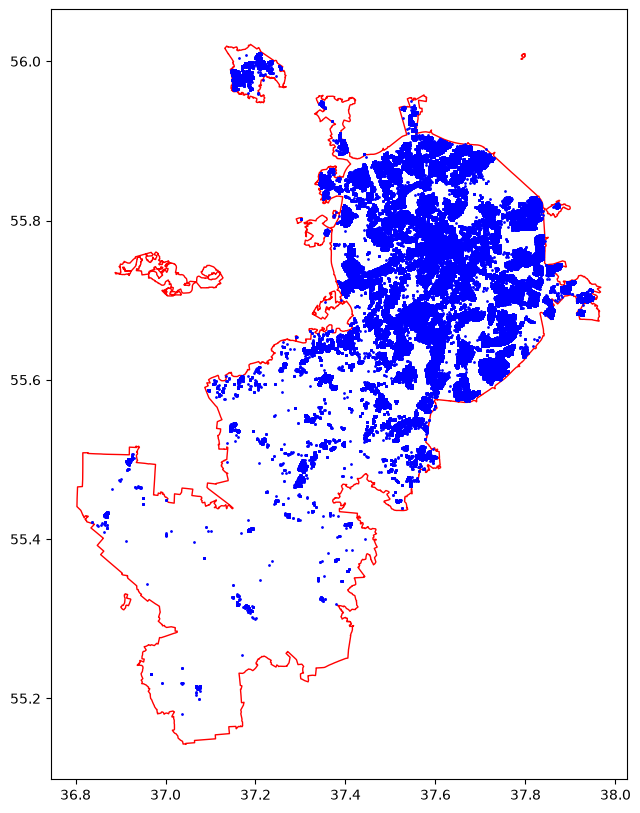

In [21]:
ax = msk.plot(
    figsize=(10, 10),
    facecolor="none",
    edgecolor="red"
)

apartments_msk.plot(
    ax=ax,
    markersize=1,
    color="blue"
)

In [22]:
apartments_msk = apartments_msk.drop(columns="index_right")

In [23]:
apartments_msk["geo_lat_round"] = apartments_msk["geo_lat"].round(4)
apartments_msk["geo_lon_round"] = apartments_msk["geo_lon"].round(4)
apartments_msk["n_at_point"] = apartments_msk.groupby(["geo_lat_round", "geo_lon_round"])["price"].transform("size")
apartments_msk["weight"] = 1 / np.sqrt(apartments_msk["n_at_point"])
apartments_msk.describe()

,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,dt,geo_lat_round,geo_lon_round,n_at_point,weight
count,3.756380e+05,375638.000000,375638.000000,375638.0,375638.000000,375638.000000,375638.000000,375638.000000,375638.000000,375638.000000,375638.000000,375638,375638.000000,375638.000000,375638.000000,375638.000000
mean,1.269046e+07,55.720624,37.576345,3.0,1.844678,8.688841,16.480897,1.861058,57.948060,12.148152,5.361300,2019-12-29 11:36:43.882184,55.720623,37.576344,298.794456,0.248081
min,1.100000e+06,55.179939,36.836900,3.0,0.000000,1.000000,1.000000,-1.000000,10.000000,0.100000,1.000000,2018-03-04 12:35:25,55.179900,36.836900,1.000000,0.019195
25%,7.050000e+06,55.638470,37.477291,3.0,1.000000,4.000000,10.000000,1.000000,39.000000,8.000000,1.000000,2019-04-03 17:50:51,55.638500,37.477300,7.000000,0.055728
50%,9.422678e+06,55.722482,37.569477,3.0,2.000000,7.000000,16.000000,2.000000,53.400000,10.500000,1.000000,2019-12-07 17:20:29.500000,55.722500,37.569500,30.000000,0.182574
75%,1.350000e+07,55.805338,37.683930,3.0,2.000000,12.000000,22.000000,3.000000,70.000000,15.400000,11.000000,2020-09-25 12:57:05,55.805300,37.683900,322.000000,0.377964
max,2.333805e+08,56.011032,37.950668,3.0,5.000000,39.000000,39.000000,9.000000,313.000000,103.130000,11.000000,2021-05-01 20:14:15,56.011000,37.950700,2714.000000,1.000000
std,1.338750e+07,0.109200,0.147740,0.0,0.793798,6.483871,7.582804,1.097140,27.935126,6.177827,4.959045,NaN,0.109200,0.147741,548.576687,0.233945


In [24]:
apartments_msk.to_parquet("./data/clean.parquet")   

C:\univer\7_semester\projects\estate_traiding_system\.venv\Scripts\python.exe
